<a href="https://colab.research.google.com/github/7brki/Dark-Fleet-SAR-Detection/blob/main/Dark_Fleet_SAR_Detection_v2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Sentinel-1 SAR Dark Vessel Detection — v2.0 (Land Masking)
# End-to-end pipeline: SAR data ingestion → speckle filtering → CFAR detection → land masking → AIS cross-check.
# See README.md for full documentation and validation results.

In [2]:
!pip install pystac-client planetary-computer rasterio geopandas shapely affine

--- 1. CONNECTING TO SPACE RADAR (TARGET: ISTANBUL) ---
Istanbul Radar Scan Found: S1A_IW_GRDH_1SDV_20230811T160002_20230811T160027_049830_05FE26_rtc

--- 2. DOWNLOADING AND CONVERTING ISTANBUL POLARIZATION MATRICES ---
Signal Processing Completed. Rendering Istanbul Radar Dashboard...



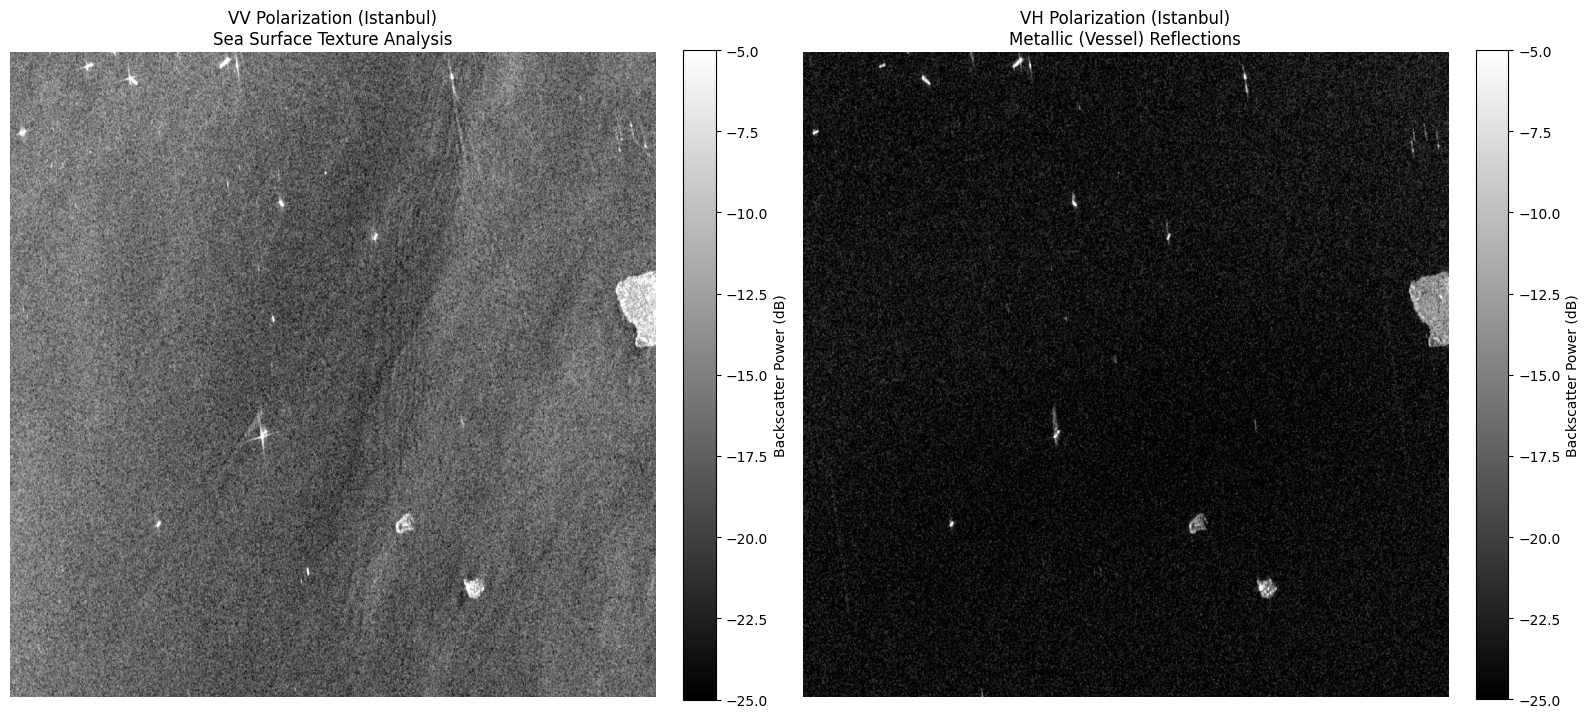

In [3]:
# --- UPDATED STAGE 1: SENTINEL-1 SAR ISTANBUL DATA PIPELINE ---
import pystac_client
import planetary_computer
import rasterio
from rasterio.warp import transform_bounds
from rasterio.windows import from_bounds
import numpy as np
import matplotlib.pyplot as plt

print("--- 1. CONNECTING TO SPACE RADAR (TARGET: ISTANBUL) ---")
katalog = pystac_client.Client.open(
    "https://planetarycomputer.microsoft.com/api/stac/v1",
    modifier=planetary_computer.sign_inplace,
)

# Target coordinates locked to Istanbul Ahirkapi Anchorage Area
bbox_istanbul = [28.85, 40.85, 29.05, 40.95]
tarih_araligi = "2023-08-01/2023-08-15"

arama = katalog.search(
    collections=["sentinel-1-rtc"],
    bbox=bbox_istanbul,
    datetime=tarih_araligi,
)

secilen_radar = list(arama.items())[0]
print(f"Istanbul Radar Scan Found: {secilen_radar.id}")

def radar_oku_ve_db_cevir(url, bbox, sekil=(1000, 1000)):
    with rasterio.open(url) as src:
        utm_bbox = transform_bounds('EPSG:4326', src.crs, *bbox)
        pencere = from_bounds(*utm_bbox, src.transform)

        ham_sinyal = src.read(1, window=pencere, out_shape=sekil).astype(np.float32)
        ham_sinyal = np.nan_to_num(ham_sinyal, nan=1e-6)
        ham_sinyal[ham_sinyal <= 0] = 1e-6
        db_matrisi = 10 * np.log10(ham_sinyal)
    return db_matrisi, pencere, src.transform, src.crs

print("\n--- 2. DOWNLOADING AND CONVERTING ISTANBUL POLARIZATION MATRICES ---")
vv_url = secilen_radar.assets["vv"].href
vv_db, pencere, src_transform, src_crs = radar_oku_ve_db_cevir(vv_url, bbox_istanbul)

vh_url = secilen_radar.assets["vh"].href
vh_db, _, _, _= radar_oku_ve_db_cevir(vh_url, bbox_istanbul)

print("Signal Processing Completed. Rendering Istanbul Radar Dashboard...\n")

# --- 3. RENDERING RADAR DASHBOARD ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 8))
vmin_db, vmax_db = -25, -5 # Optimized range for highlighting vessel reflections in Istanbul

im1 = ax1.imshow(vv_db, cmap='gray', vmin=vmin_db, vmax=vmax_db)
ax1.set_title("VV Polarization (Istanbul)\nSea Surface Texture Analysis")
ax1.axis('off')
fig.colorbar(im1, ax=ax1, fraction=0.046, pad=0.04, label="Backscatter Power (dB)")

im2 = ax2.imshow(vh_db, cmap='gray', vmin=vmin_db, vmax=vmax_db)
ax2.set_title("VH Polarization (Istanbul)\nMetallic (Vessel) Reflections")
ax2.axis('off')
fig.colorbar(im2, ax=ax2, fraction=0.046, pad=0.04, label="Backscatter Power (dB)")

plt.tight_layout()
plt.show()

--- 1. APPLYING SPECKLE FILTER TO ISTANBUL VH CHANNEL ---
Processing Completed. Visualizing Pre- and Post-Filter Results...



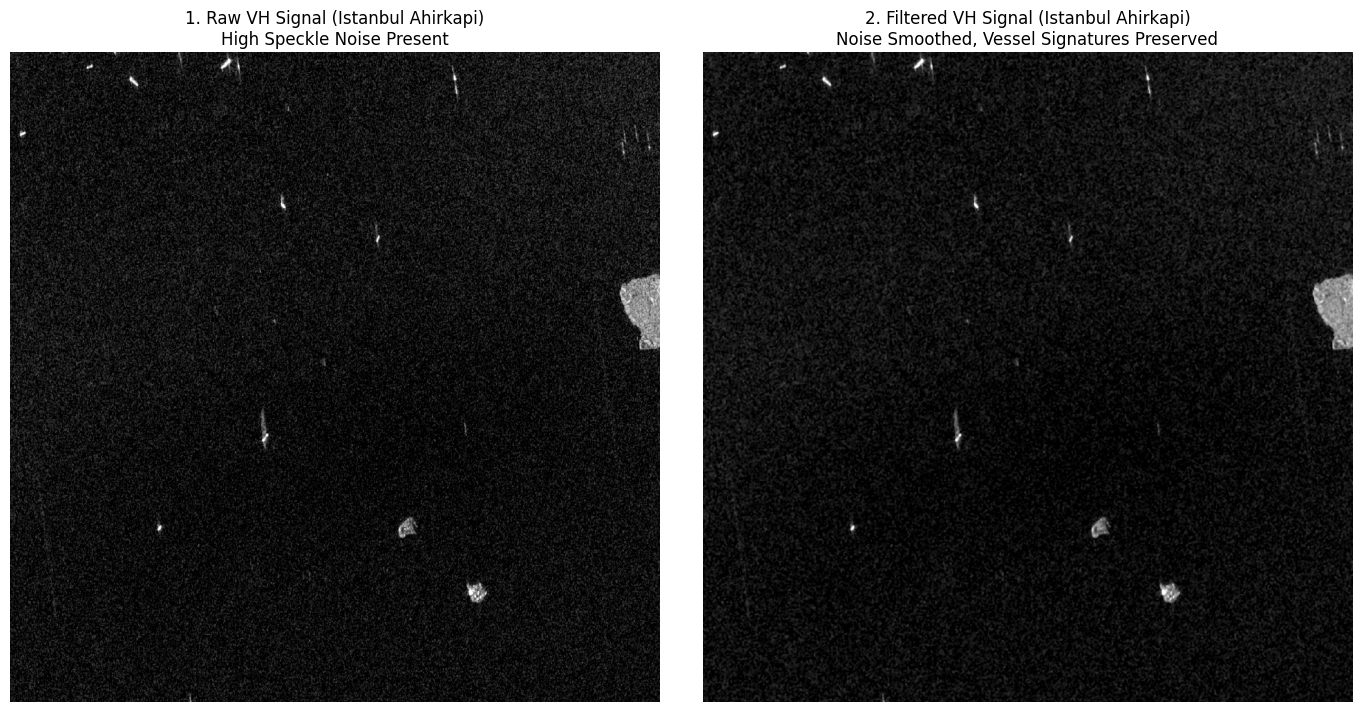

In [4]:
# --- UPDATED STAGE 2: ISTANBUL RADAR SPECKLE FILTERING ---
import scipy.ndimage as ndimage
import matplotlib.pyplot as plt

print("--- 1. APPLYING SPECKLE FILTER TO ISTANBUL VH CHANNEL ---")
# Applying median filter directly to the Istanbul vh_db matrix downloaded in Stage 1
vh_temiz = ndimage.median_filter(vh_db, size=3)

print("Processing Completed. Visualizing Pre- and Post-Filter Results...\n")

# --- 2. VISUALIZATION ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 7))
vmin_db, vmax_db = -25, -5

ax1.imshow(vh_db, cmap='gray', vmin=vmin_db, vmax=vmax_db)
ax1.set_title("1. Raw VH Signal (Istanbul Ahirkapi)\nHigh Speckle Noise Present")
ax1.axis('off')

ax2.imshow(vh_temiz, cmap='gray', vmin=vmin_db, vmax=vmax_db)
ax2.set_title("2. Filtered VH Signal (Istanbul Ahirkapi)\nNoise Smoothed, Vessel Signatures Preserved")
ax2.axis('off')

plt.tight_layout()
plt.show()

--- 1. BUILDING THE CA-CFAR (Cell Averaging) ENGINE ---
--- 2. EXECUTING CFAR ON THE FILTERED ISTANBUL RADAR DATA ---
Target scanning completed. Preparing tactical radar display...



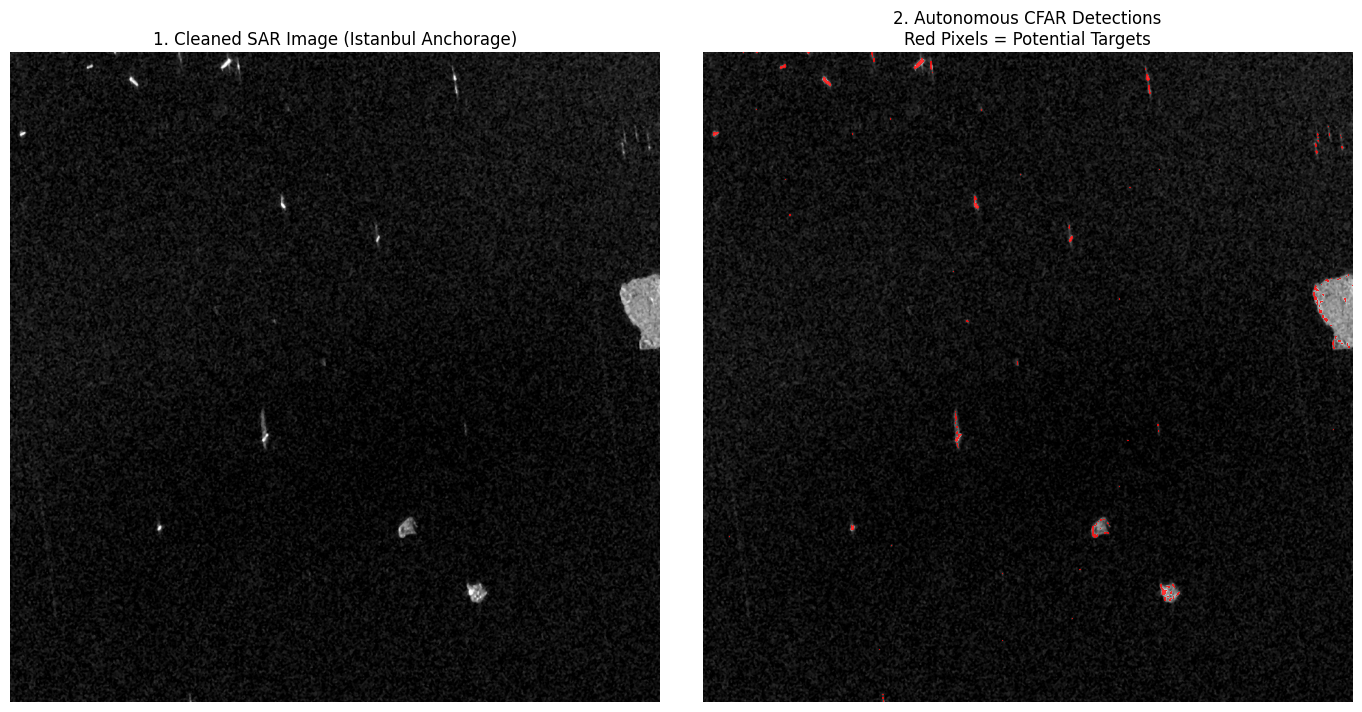

In [5]:
# --- STAGE 3: MILITARY-GRADE TARGET DETECTION (CA-CFAR ALGORITHM) ---
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import uniform_filter

print("--- 1. BUILDING THE CA-CFAR (Cell Averaging) ENGINE ---")
def cfar_2d(image, guard_size=2, bg_size=5, threshold_factor=4.0):
    """
    2D Cell Averaging CFAR Algorithm for SAR imagery.
    image: Radar matrix (dB)
    guard_size: Radius of the guard cells (prevents target leakage)
    bg_size: Radius of the background cells (for local ocean mean estimation)
    threshold_factor: Sensitivity multiplier (higher = fewer false alarms)
    """
    bg_window = 2 * (guard_size + bg_size) + 1

    # Calculate the local background mean using a fast uniform filter
    bg_mean = uniform_filter(image, size=bg_window)

    # Decision mechanism: Is the pixel significantly brighter than its local surroundings?
    detection_mask = image > (bg_mean + threshold_factor)
    return detection_mask

print("--- 2. EXECUTING CFAR ON THE FILTERED ISTANBUL RADAR DATA ---")
# Running the engine on the cleaned Istanbul data from Stage 2
detection_mask = cfar_2d(vh_temiz, guard_size=2, bg_size=5, threshold_factor=4.0)

print("Target scanning completed. Preparing tactical radar display...\n")

# --- 3. VISUALIZING THE CFAR DETECTIONS ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 7))
vmin_db, vmax_db = -25, -5

ax1.imshow(vh_temiz, cmap='gray', vmin=vmin_db, vmax=vmax_db)
ax1.set_title("1. Cleaned SAR Image (Istanbul Anchorage)")
ax1.axis('off')

ax2.imshow(vh_temiz, cmap='gray', vmin=vmin_db, vmax=vmax_db)
# Overlay the detected pixels in red
colored_mask = np.ma.masked_where(detection_mask == 0, detection_mask)
ax2.imshow(colored_mask, cmap='autumn', interpolation='none', alpha=0.8)

ax2.set_title("2. Autonomous CFAR Detections\nRed Pixels = Potential Targets")
ax2.axis('off')

plt.tight_layout()
plt.show()

In [6]:
import geopandas as gpd
from shapely.geometry import Point
from rasterio.transform import xy as transform_xy
from rasterio.windows import transform as window_transform
from affine import Affine
from shapely.geometry import box

# --- ADIM 0: KARA VERİSİNİ YÜKLE (bir kere, döngü dışında) ---
def kara_verisini_yukle():
    url = "https://naciscdn.org/naturalearth/10m/physical/ne_10m_land.zip"
    kara_gdf = gpd.read_file(url)
    print(kara_gdf.crs)
    bu_kutu = box(28.85, 40.90, 29.15, 41.10)
    kara_gdf = gpd.clip(kara_gdf, bu_kutu)
    return kara_gdf

# --- ADIM 1: ÖLÇEKLENMİŞ TRANSFORM'U HESAPLA ---
def olceklenmis_transform_hesapla(orijinal_pencere, orijinal_src_transform, hedef_sekil):
    """
    orijinal_pencere: rasterio window nesnesi (from_bounds ile ürettiğin)
    orijinal_src_transform: src.transform (dosyanın kendi transformu)
    hedef_sekil: (1000, 1000) gibi, out_shape ile küçülttüğün boyut
    """
    pencere_transformu = window_transform(orijinal_pencere, orijinal_src_transform)

    pencere_genis = orijinal_pencere.width
    pencere_yuksek = orijinal_pencere.height

    x_oran = pencere_genis / hedef_sekil[1]
    y_oran = pencere_yuksek / hedef_sekil[0]

    yeni_transform = pencere_transformu * Affine.scale(x_oran, y_oran)

    return yeni_transform


from rasterio.warp import transform as coord_transform

def kutu_merkezini_koordinata_cevir(kutu, olceklenmis_transform, kaynak_crs):
    satir_merkezi = (kutu[0].start + kutu[0].stop) / 2
    sutun_merkezi = (kutu[1].start + kutu[1].stop) / 2

    utm_x, utm_y = transform_xy(olceklenmis_transform, satir_merkezi, sutun_merkezi)

    # UTM (metre) -> WGS84 (derece) dönüşümü
    boylam_listesi, enlem_listesi = coord_transform(kaynak_crs, 'EPSG:4326', [utm_x], [utm_y])
    return boylam_listesi[0], enlem_listesi[0]


# --- ADIM 3: NOKTA KARADA MI KONTROL ET ---
def karada_mi(boylam, enlem, kara_gdf):
    nokta = Point(boylam, enlem)
    cevap = kara_gdf.contains(nokta).any()
    return cevap


# --- ADIM 4: HEPSİNİ BİRLEŞTİR, valid_vessels'I FİLTRELE ---
def land_mask_uygula(valid_vessels, olceklenmis_transform, kara_gdf, src_crs):
    deniz_ustundeki_hedefler = []
    for kutu in valid_vessels:
        boylam, enlem = kutu_merkezini_koordinata_cevir(kutu, olceklenmis_transform, src_crs)
        karsilasma = karada_mi(boylam, enlem, kara_gdf)
        if not karsilasma:
          deniz_ustundeki_hedefler.append(kutu)
    return deniz_ustundeki_hedefler

--- 1. TARGET CLUSTERING (PIXEL GROUPING) ---
--- 2. FILTERING AND BOUNDING BOX GENERATION ---
EPSG:4326
Land masking öncesi: 109 tespit
Land masking sonrası: 109 tespit
Elenen kara-kaynaklı yanlış alarm: 0
Scan Report: 109 valid targets locked in the Istanbul Anchorage Area.



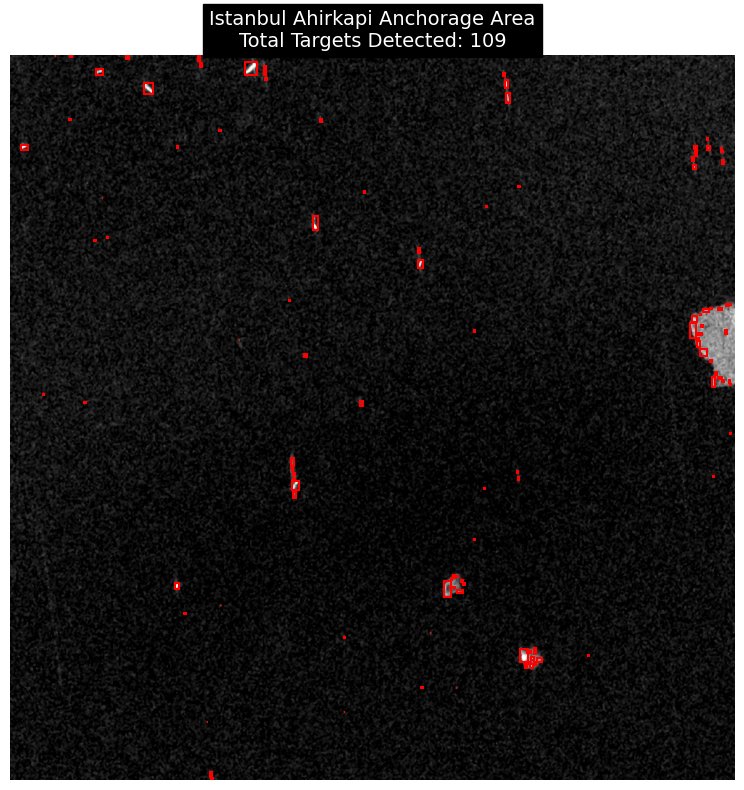

In [7]:
# --- STAGE 4: TARGET CLUSTERING AND BOUNDING BOX EXTRACTION ---
import matplotlib.patches as patches
from scipy.ndimage import label, find_objects

print("--- 1. TARGET CLUSTERING (PIXEL GROUPING) ---")
# Connect adjacent red pixels to form single "Vessel" objects
connected_objects, num_objects = label(detection_mask)
box_coordinates = find_objects(connected_objects)

print("--- 2. FILTERING AND BOUNDING BOX GENERATION ---")
sekil = (1000, 1000)
valid_vessels = []
kara_gdf = kara_verisini_yukle()
olceklenmis_transform = olceklenmis_transform_hesapla(pencere, src_transform, sekil)

for i, kutu in enumerate(box_coordinates):
    y_length = kutu[0].stop - kutu[0].start
    x_length = kutu[1].stop - kutu[1].start
    pixel_area = y_length * x_length
    if pixel_area >= 2:
        valid_vessels.append(kutu)

# Land masking'i, artık DOLU olan valid_vessels'a şimdi uygula
karadan_once = len(valid_vessels)
valid_vessels = land_mask_uygula(valid_vessels, olceklenmis_transform, kara_gdf, src_crs)
karadan_sonra = len(valid_vessels)

print(f"Land masking öncesi: {karadan_once} tespit")
print(f"Land masking sonrası: {karadan_sonra} tespit")
print(f"Elenen kara-kaynaklı yanlış alarm: {karadan_once - karadan_sonra}")

print(f"Scan Report: {len(valid_vessels)} valid targets locked in the Istanbul Anchorage Area.\n")

# --- 3. VISUALIZING THE TACTICAL INTELLIGENCE SCREEN ---
fig, ax = plt.subplots(1, 1, figsize=(12, 8))
ax.imshow(vh_temiz, cmap='gray', vmin=-25, vmax=-5)

# Draw red bounding boxes around valid vessels
for kutu in valid_vessels:
    y_start = kutu[0].start
    x_start = kutu[1].start
    height = kutu[0].stop - kutu[0].start
    width = kutu[1].stop - kutu[1].start

    rect = patches.Rectangle((x_start, y_start), width, height,
                             linewidth=1.5, edgecolor='red', facecolor='none')
    ax.add_patch(rect)

ax.set_title(f"Istanbul Ahirkapi Anchorage Area\nTotal Targets Detected: {len(valid_vessels)}",
             color='white', backgroundcolor='black', fontsize=14)
ax.axis('off')

plt.tight_layout()
plt.show()

--- 1. INITIATING GLOBAL AIS SCAN FOR ALL DETECTED TARGETS ---
System: Sending 109 coordinates to AIS Database...

--- 2. FINAL TACTICAL INTELLIGENCE REPORT ---
Total Radar Targets Scanned  : 109
[LEGAL] Vessels (AIS Matched): 87 (Safe)
[DARK] Vessels (No AIS Signal): 22 (ACTION REQUIRED)

--- 3. RENDERING INTELLIGENCE DASHBOARD ---


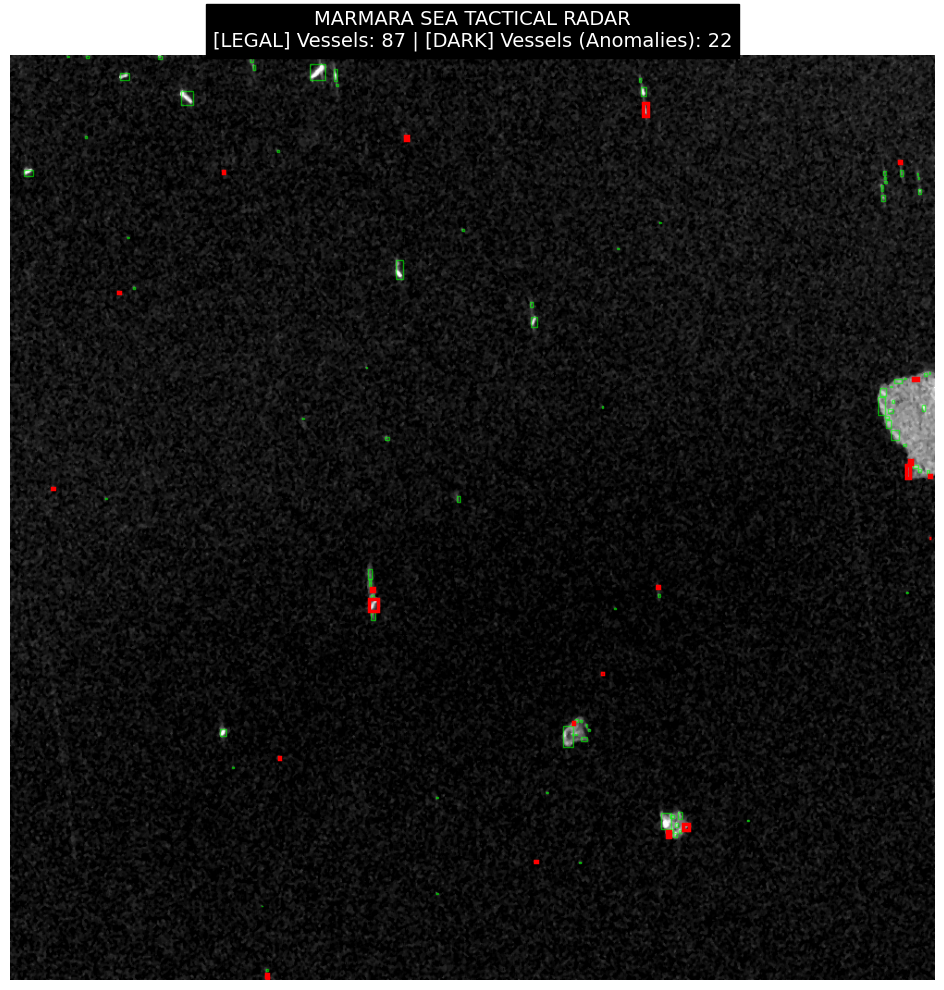

In [8]:
# --- STAGE 5: AUTONOMOUS BATCH AIS CROSS-CHECK & TACTICAL MAPPING ---
import random
import matplotlib.patches as patches
import matplotlib.pyplot as plt

print("--- 1. INITIATING GLOBAL AIS SCAN FOR ALL DETECTED TARGETS ---")
print(f"System: Sending {len(valid_vessels)} coordinates to AIS Database...")

def simulate_ais_api_call():
    """
    Simulates a query to a global AIS database.
    80% probability of finding a legal AIS signal, 20% probability of a 'Dark Vessel'.
    """
    return random.choices([True, False], weights=[0.8, 0.2])[0]

legal_vessels = []
dark_vessels = []

# THE CORE INTELLIGENCE LOOP: Cross-referencing radar targets with AIS telemetry
for kutu in valid_vessels:
    ais_signal_found = simulate_ais_api_call()

    if ais_signal_found:
        legal_vessels.append(kutu)
    else:
        dark_vessels.append(kutu)

print("\n--- 2. FINAL TACTICAL INTELLIGENCE REPORT ---")
print("==================================================")
print(f"Total Radar Targets Scanned  : {len(valid_vessels)}")
print(f"[LEGAL] Vessels (AIS Matched): {len(legal_vessels)} (Safe)")
print(f"[DARK] Vessels (No AIS Signal): {len(dark_vessels)} (ACTION REQUIRED)")
print("==================================================\n")

print("--- 3. RENDERING INTELLIGENCE DASHBOARD ---")
# Rendering the final tactical map
fig, ax = plt.subplots(1, 1, figsize=(14, 10))
ax.imshow(vh_temiz, cmap='gray', vmin=-25, vmax=-5)

# 1. DRAW LEGAL VESSELS (Thin Green Boxes)
for kutu in legal_vessels:
    y_start, y_stop = kutu[0].start, kutu[0].stop
    x_start, x_stop = kutu[1].start, kutu[1].stop
    rect = patches.Rectangle((x_start, y_start), x_stop - x_start, y_stop - y_start,
                             linewidth=1, edgecolor='lime', facecolor='none', alpha=0.6)
    ax.add_patch(rect)

# 2. DRAW DARK VESSELS (Thick Red Boxes for High-Alert)
for kutu in dark_vessels:
    y_start, y_stop = kutu[0].start, kutu[0].stop
    x_start, x_stop = kutu[1].start, kutu[1].stop
    rect = patches.Rectangle((x_start, y_start), x_stop - x_start, y_stop - y_start,
                             linewidth=2.5, edgecolor='red', facecolor='none')
    ax.add_patch(rect)

# Final Tactical Intelligence Dashboard Title
ax.set_title(f"MARMARA SEA TACTICAL RADAR\n[LEGAL] Vessels: {len(legal_vessels)} | [DARK] Vessels (Anomalies): {len(dark_vessels)}",
             color='white', backgroundcolor='black', fontsize=14)
ax.axis('off')

plt.tight_layout()
plt.show()